In [9]:
import os
import math
import numpy as np
from PIL import Image
from tqdm import tqdm
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam

# Enable mixed precision
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')
print("Mixed precision policy:", mixed_precision.global_policy())

print("TensorFlow:", tf.__version__)


Mixed precision policy: <DTypePolicy "mixed_float16">
TensorFlow: 2.19.0


In [10]:
# Paths
BASE_DIR = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\processed_images"        # your dataset root
OUT_BASE = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\processed with gan 2"    # new output folder
os.makedirs(OUT_BASE, exist_ok=True)

# Image & GAN parameters
IMG_SIZE = 64
CHANNELS = 3
IMAGE_SHAPE = (IMG_SIZE, IMG_SIZE, CHANNELS)

latent_dim = 128
batch_size = 32
n_epochs = 50            # Increase for better quality
lr = 1e-4
beta1, beta2 = 0.0, 0.99

fm_weight = 10.0
diversity_weight = 2.0

# Get the max class count for balancing
def count_images_in_class(path):
    return len([f for f in os.listdir(path) if f.lower().endswith(('.png','.jpg','.jpeg'))])

max_class_count = max(count_images_in_class(os.path.join(BASE_DIR, c)) 
                      for c in os.listdir(BASE_DIR) 
                      if os.path.isdir(os.path.join(BASE_DIR, c)))

print("Max class count:", max_class_count)


Max class count: 6705


In [11]:
def list_image_files(class_dir):
    exts = ('.jpg', '.jpeg', '.png')
    return [os.path.join(class_dir, f) for f in os.listdir(class_dir) if f.lower().endswith(exts)]

def image_batch_generator(paths, batch_size, img_size, augment=False):
    batch = []
    for p in paths:
        try:
            img = Image.open(p).convert('RGB').resize((img_size, img_size))
            arr = np.asarray(img, dtype=np.float32) / 127.5 - 1.0
            batch.append(arr)
            if len(batch) == batch_size:
                yield np.stack(batch, axis=0)
                batch = []
        except:
            continue
    if batch:
        yield np.stack(batch, axis=0)


In [12]:
# Fixed NoiseInjection
class NoiseInjection(layers.Layer):
    def __init__(self):
        super().__init__()
        self.weight = self.add_weight(shape=(1,), initializer='zeros', trainable=True)
    def call(self, x, noise=None):
        if noise is None:
            b, h, w, _ = tf.unstack(tf.shape(x))
            noise = tf.random.normal(shape=(b, h, w, 1))
        # Cast noise to match x's dtype
        noise = tf.cast(noise, x.dtype)
        weight = tf.cast(self.weight, x.dtype)
        return x + weight * noise

# Residual Block
def ResidualBlock(x, filters):
    y = layers.Conv2D(filters, 3, padding='same')(x)
    y = layers.BatchNormalization()(y)
    y = layers.LeakyReLU(0.2)(y)
    y = layers.Conv2D(filters, 3, padding='same')(y)
    y = layers.BatchNormalization()(y)
    return layers.add([x, y])

# Self-Attention
class SelfAttention(layers.Layer):
    def __init__(self, channels):
        super().__init__()
        self.query = layers.Conv2D(channels//8, 1, padding='same')
        self.key   = layers.Conv2D(channels//8, 1, padding='same')
        self.value = layers.Conv2D(channels, 1, padding='same')
        self.gamma = self.add_weight(shape=(1,), initializer='zeros', trainable=True)
    def call(self, x):
        b, h, w, c = tf.shape(x)[0], x.shape[1], x.shape[2], x.shape[3]
        q = tf.reshape(self.query(x), [b, -1, c//8])
        k = tf.reshape(self.key(x),   [b, -1, c//8])
        v = tf.reshape(self.value(x), [b, -1, c])
        attn = tf.nn.softmax(tf.matmul(q, k, transpose_b=True))
        out = tf.matmul(attn, v)
        out = tf.reshape(out, [-1, h, w, c])
        return self.gamma * out + x


In [13]:
def build_generator(latent_dim=128, img_size=64, channels=3):
    init = tf.keras.initializers.RandomNormal(0, 0.02)
    inp = layers.Input(shape=(latent_dim,))
    x = layers.Dense((img_size//8)*(img_size//8)*256, kernel_initializer=init)(inp)
    x = layers.Reshape((img_size//8, img_size//8, 256))(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = NoiseInjection()(x)

    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(256, 3, padding='same', kernel_initializer=init)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = ResidualBlock(x, 256)
    x = NoiseInjection()(x)
    x = SelfAttention(256)(x)

    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(128, 3, padding='same', kernel_initializer=init)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = ResidualBlock(x, 128)
    x = NoiseInjection()(x)

    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(64, 3, padding='same', kernel_initializer=init)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = ResidualBlock(x, 64)

    out = layers.Conv2D(channels, 3, padding='same', activation='tanh', kernel_initializer=init, dtype='float32')(x)
    return tf.keras.Model(inp, out, name='custom_generator')

def build_discriminator_global(img_size=64, channels=3):
    inp = layers.Input(shape=(img_size, img_size, channels))
    x = layers.Conv2D(64, 4, strides=2, padding='same')(inp)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Conv2D(128, 4, strides=2, padding='same')(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Conv2D(256, 4, strides=2, padding='same')(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Flatten()(x)
    out = layers.Dense(1, dtype='float32')(x)
    return tf.keras.Model(inp, out)

def build_discriminator_patch(img_size=64, channels=3):
    inp = layers.Input(shape=(img_size, img_size, channels))
    x = layers.Conv2D(64, 4, strides=2, padding='same')(inp)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Conv2D(128, 4, strides=2, padding='same')(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Conv2D(256, 4, strides=2, padding='same')(x)
    x = layers.LeakyReLU(0.2)(x)
    out = layers.Conv2D(1, 4, padding='same', dtype='float32')(x)
    return tf.keras.Model(inp, out)


In [14]:
def d_hinge_loss(real, fake):
    return tf.reduce_mean(tf.nn.relu(1.0 - real)) + tf.reduce_mean(tf.nn.relu(1.0 + fake))

def g_hinge_loss(fake):
    return -tf.reduce_mean(fake)

def feature_matching_loss(real_feats, fake_feats):
    return tf.reduce_mean([tf.reduce_mean(tf.abs(r - f)) for r, f in zip(real_feats, fake_feats)])

def diversity_loss(generator, z1, z2):
    f1 = generator(z1)
    f2 = generator(z2)
    return tf.reduce_mean(tf.abs(f1 - f2)) / (tf.reduce_mean(tf.abs(z1 - z2)) + 1e-8)

def build_disc_with_intermediate(disc_model):
    inter_outs = [layer.output for layer in disc_model.layers if isinstance(layer, layers.LeakyReLU)]
    inter_outs.append(disc_model.output)
    return tf.keras.Model(disc_model.input, inter_outs)


In [15]:
from IPython.display import display

def train_custom_gan_per_class(
    class_name, class_dir, out_dir,
    img_size=IMG_SIZE, latent_dim=latent_dim,
    batch_size=batch_size, n_epochs=n_epochs, lr=lr,
    fm_weight=fm_weight, diversity_weight=diversity_weight,
    preview_interval=10
):
    print(f"\n=== Training GAN for class: {class_name} ===")
    os.makedirs(out_dir, exist_ok=True)

    # --- Filter: Only load real images starting with "ISIC" ---
    image_paths = [
        p for p in list_image_files(class_dir)
        if os.path.basename(p).startswith("ISIC")
    ]
    real_count = len(image_paths)
    needed_gen = max_class_count - real_count

    # Print info before training
    print(f"Training on {real_count} real images for class '{class_name}'.")
    if needed_gen > 0:
        print(f"Will generate {needed_gen} new images to match max count ({max_class_count}).")
    else:
        print(f"No extra images will be generated for class '{class_name}' (already at max count).")

    if real_count < 10:
        print(f"Skipping {class_name}: only {real_count} real images.")
        return

    # Build models
    gen = build_generator(latent_dim, img_size, CHANNELS)
    disc_glob = build_discriminator_global(img_size, CHANNELS)
    disc_patch = build_discriminator_patch(img_size, CHANNELS)
    disc_glob_inter = build_disc_with_intermediate(disc_glob)

    # Optimizers
    g_opt = Adam(learning_rate=lr, beta_1=beta1, beta_2=beta2)
    d_opt = Adam(learning_rate=lr, beta_1=beta1, beta_2=beta2)

    # Fixed latent vector for previews
    fixed_z = np.random.normal(size=(16, latent_dim)).astype('float32')

    for epoch in range(n_epochs):
        np.random.shuffle(image_paths)
        batch_gen = image_batch_generator(image_paths, batch_size, img_size)

        step = 0
        for real_batch in batch_gen:
            b = real_batch.shape[0]

            # --- Discriminator ---
            z = np.random.normal(size=(b, latent_dim)).astype('float32')
            with tf.GradientTape() as d_tape:
                fake_imgs = gen(z, training=True)
                real_glob = disc_glob(real_batch, training=True)
                fake_glob = disc_glob(fake_imgs, training=True)
                real_patch = tf.reduce_mean(disc_patch(real_batch, training=True), axis=[1,2,3])
                fake_patch = tf.reduce_mean(disc_patch(fake_imgs, training=True), axis=[1,2,3])

                d_loss = tf.cast(d_hinge_loss(real_glob, fake_glob), tf.float32) \
                       + tf.cast(d_hinge_loss(real_patch, fake_patch), tf.float32)

            d_grads = d_tape.gradient(d_loss, disc_glob.trainable_variables + disc_patch.trainable_variables)
            d_opt.apply_gradients(zip(d_grads, disc_glob.trainable_variables + disc_patch.trainable_variables))

            # --- Generator ---
            z1 = np.random.normal(size=(b, latent_dim)).astype('float32')
            z2 = np.random.normal(size=(b, latent_dim)).astype('float32')
            with tf.GradientTape() as g_tape:
                fake_imgs = gen(z1, training=True)
                fake_glob = disc_glob(fake_imgs, training=True)
                fake_patch = tf.reduce_mean(disc_patch(fake_imgs, training=True), axis=[1,2,3])
                g_adv = g_hinge_loss(fake_glob) + g_hinge_loss(fake_patch)
                fm_loss_val = feature_matching_loss(
                    [tf.stop_gradient(r) for r in disc_glob_inter(real_batch)[:-1]],
                    disc_glob_inter(fake_imgs)[:-1]
                )
                div_loss_val = diversity_loss(gen, z1, z2)

                g_loss = tf.cast(g_adv, tf.float32) \
                       + tf.cast(fm_weight * fm_loss_val, tf.float32) \
                       + tf.cast(diversity_weight * div_loss_val, tf.float32)

            g_grads = g_tape.gradient(g_loss, gen.trainable_variables)
            g_opt.apply_gradients(zip(g_grads, gen.trainable_variables))

            # --- Print every 10 batches ---
            if step % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} Step {step} — D: {d_loss:.4f}, G: {g_loss:.4f}")
            step += 1

        # --- End of epoch summary ---
        print(f"Epoch {epoch+1} complete — Final D: {d_loss:.4f}, G: {g_loss:.4f}")

        # Save + display preview
        if (epoch+1) % preview_interval == 0 or epoch == 0:
            preview_dir = os.path.join(out_dir, "previews")
            os.makedirs(preview_dir, exist_ok=True)
            samples = gen(fixed_z, training=False).numpy()
            samples = ((samples + 1.0) * 127.5).astype(np.uint8)

            # Make a simple grid (4x4)
            grid_rows, grid_cols = 4, 4
            grid_img = Image.new('RGB', (IMG_SIZE*grid_cols, IMG_SIZE*grid_rows))
            for i, img in enumerate(samples):
                r, c = divmod(i, grid_cols)
                grid_img.paste(Image.fromarray(img), (c*IMG_SIZE, r*IMG_SIZE))

            grid_path = os.path.join(preview_dir, f"epoch_{epoch+1:03d}.png")
            grid_img.save(grid_path)
            print(f"Saved preview: {grid_path}")
            display(grid_img)  # show in Jupyter

    # Balanced image generation at the end
    if needed_gen > 0:
        print(f"Generating {needed_gen} images for {class_name}...")
        gen_count = 0
        while gen_count < needed_gen:
            z = np.random.normal(size=(min(batch_size, needed_gen - gen_count), latent_dim)).astype('float32')
            samples = gen(z, training=False).numpy()
            samples = ((samples + 1.0) * 127.5).astype(np.uint8)
            for img in samples:
                fname = f"gen_{class_name}_{gen_count:05d}.png"
                Image.fromarray(img).save(os.path.join(out_dir, fname))
                gen_count += 1
        print(f"Done: {gen_count} images saved for {class_name}.")



=== Training GAN for class: AKIEC ===
Training on 327 real images for class 'AKIEC'.
Will generate 6378 new images to match max count (6705).


c:\Users\devgo\OneDrive\Desktop\project\.venv\Lib\site-packages\keras\src\layers\layer.py:1474: UserWarning: Layer 'self_attention_1' looks like it has unbuilt state, but Keras is not able to trace the layer `call()` in order to build it automatically. Possible causes:
1. The `call()` method of your layer may be crashing. Try to `__call__()` the layer eagerly on some test input first to see if it works. E.g. `x = np.random.random((3, 4)); y = layer(x)`
2. If the `call()` method is correct, then you may need to implement the `def build(self, input_shape)` method on your layer. It should create all variables used by the layer (e.g. by calling `layer.build()` on all its children layers).
Exception encountered: ''Input 'y' of 'AddV2' Op has type float16 that does not match type float32 of argument 'x'.''
  warnings.warn(


Epoch 1/50 Step 0 — D: 4.0111, G: nan
Epoch 1/50 Step 10 — D: 2.8184, G: 0.1626
Epoch 1 complete — Final D: 2.8184, G: 0.1626
Saved preview: C:\Users\devgo\OneDrive\Desktop\project\data\processed with gan 2\AKIEC\previews\epoch_001.png


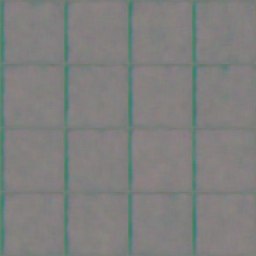

Epoch 2/50 Step 0 — D: 2.6668, G: nan
Epoch 2/50 Step 10 — D: 2.6293, G: 0.6054
Epoch 2 complete — Final D: 2.6293, G: 0.6054
Epoch 3/50 Step 0 — D: 2.4446, G: nan
Epoch 3/50 Step 10 — D: 2.1025, G: 1.0893
Epoch 3 complete — Final D: 2.1025, G: 1.0893
Epoch 4/50 Step 0 — D: 2.4623, G: nan
Epoch 4/50 Step 10 — D: 1.5898, G: 0.2393
Epoch 4 complete — Final D: 1.5898, G: 0.2393
Epoch 5/50 Step 0 — D: 2.9685, G: nan
Epoch 5/50 Step 10 — D: 1.4613, G: 1.4383
Epoch 5 complete — Final D: 1.4613, G: 1.4383
Epoch 6/50 Step 0 — D: 1.7169, G: nan
Epoch 6/50 Step 10 — D: 0.9974, G: 2.4090
Epoch 6 complete — Final D: 0.9974, G: 2.4090
Epoch 7/50 Step 0 — D: 2.7526, G: nan
Epoch 7/50 Step 10 — D: 3.7510, G: 0.7605
Epoch 7 complete — Final D: 3.7510, G: 0.7605
Epoch 8/50 Step 0 — D: 3.6006, G: nan
Epoch 8/50 Step 10 — D: 2.7355, G: 0.2982
Epoch 8 complete — Final D: 2.7355, G: 0.2982
Epoch 9/50 Step 0 — D: 2.8096, G: nan
Epoch 9/50 Step 10 — D: 4.2900, G: -0.2299
Epoch 9 complete — Final D: 4.2900, G

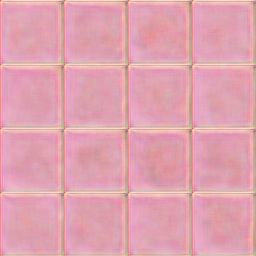

Epoch 11/50 Step 0 — D: 4.1696, G: nan
Epoch 11/50 Step 10 — D: 4.3557, G: 0.1994
Epoch 11 complete — Final D: 4.3557, G: 0.1994
Epoch 12/50 Step 0 — D: 4.2064, G: nan
Epoch 12/50 Step 10 — D: 4.2299, G: 0.1023
Epoch 12 complete — Final D: 4.2299, G: 0.1023
Epoch 13/50 Step 0 — D: 4.1293, G: nan
Epoch 13/50 Step 10 — D: 3.9535, G: -0.1033
Epoch 13 complete — Final D: 3.9535, G: -0.1033
Epoch 14/50 Step 0 — D: 4.0698, G: nan
Epoch 14/50 Step 10 — D: 4.0895, G: 0.0248
Epoch 14 complete — Final D: 4.0895, G: 0.0248
Epoch 15/50 Step 0 — D: 3.9830, G: nan
Epoch 15/50 Step 10 — D: 3.9303, G: 0.8663
Epoch 15 complete — Final D: 3.9303, G: 0.8663
Epoch 16/50 Step 0 — D: 3.9466, G: nan
Epoch 16/50 Step 10 — D: 3.9879, G: -0.1214
Epoch 16 complete — Final D: 3.9879, G: -0.1214
Epoch 17/50 Step 0 — D: 4.0066, G: nan
Epoch 17/50 Step 10 — D: 3.8660, G: 0.0075
Epoch 17 complete — Final D: 3.8660, G: 0.0075
Epoch 18/50 Step 0 — D: 3.9923, G: nan
Epoch 18/50 Step 10 — D: 3.9712, G: 0.0878
Epoch 18 co

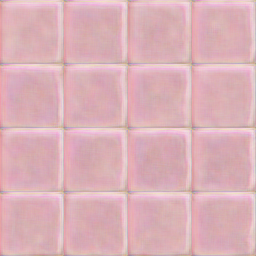

Epoch 21/50 Step 0 — D: 3.9763, G: nan
Epoch 21/50 Step 10 — D: 4.0860, G: -0.1778
Epoch 21 complete — Final D: 4.0860, G: -0.1778
Epoch 22/50 Step 0 — D: 3.9762, G: nan
Epoch 22/50 Step 10 — D: 3.8267, G: 0.4359
Epoch 22 complete — Final D: 3.8267, G: 0.4359
Epoch 23/50 Step 0 — D: 4.0424, G: nan
Epoch 23/50 Step 10 — D: 4.0447, G: -0.0611
Epoch 23 complete — Final D: 4.0447, G: -0.0611
Epoch 24/50 Step 0 — D: 4.0305, G: nan
Epoch 24/50 Step 10 — D: 3.9197, G: 1.1070
Epoch 24 complete — Final D: 3.9197, G: 1.1070
Epoch 25/50 Step 0 — D: 4.1645, G: nan
Epoch 25/50 Step 10 — D: 3.9760, G: 0.3657
Epoch 25 complete — Final D: 3.9760, G: 0.3657
Epoch 26/50 Step 0 — D: 3.9240, G: 0.3310
Epoch 26/50 Step 10 — D: 3.9174, G: 0.2156
Epoch 26 complete — Final D: 3.9174, G: 0.2156
Epoch 27/50 Step 0 — D: 3.9599, G: 0.2198
Epoch 27/50 Step 10 — D: 3.9598, G: 0.1358
Epoch 27 complete — Final D: 3.9598, G: 0.1358
Epoch 28/50 Step 0 — D: 3.9777, G: nan
Epoch 28/50 Step 10 — D: 3.9501, G: 0.0505
Epoch

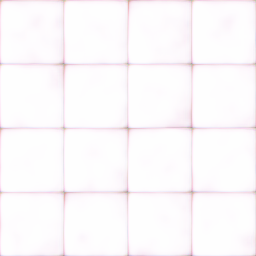

Epoch 31/50 Step 0 — D: 3.9812, G: nan
Epoch 31/50 Step 10 — D: 4.0466, G: 0.6058
Epoch 31 complete — Final D: 4.0466, G: 0.6058
Epoch 32/50 Step 0 — D: 4.1410, G: nan
Epoch 32/50 Step 10 — D: 4.0399, G: 0.0390
Epoch 32 complete — Final D: 4.0399, G: 0.0390
Epoch 33/50 Step 0 — D: 3.9630, G: nan
Epoch 33/50 Step 10 — D: 3.9667, G: -0.0454
Epoch 33 complete — Final D: 3.9667, G: -0.0454
Epoch 34/50 Step 0 — D: 3.9731, G: nan
Epoch 34/50 Step 10 — D: 4.0610, G: 0.0701
Epoch 34 complete — Final D: 4.0610, G: 0.0701
Epoch 35/50 Step 0 — D: 3.9657, G: nan
Epoch 35/50 Step 10 — D: 4.0088, G: -0.7292
Epoch 35 complete — Final D: 4.0088, G: -0.7292
Epoch 36/50 Step 0 — D: 4.0310, G: -0.4034
Epoch 36/50 Step 10 — D: 3.9749, G: -0.6243
Epoch 36 complete — Final D: 3.9749, G: -0.6243
Epoch 37/50 Step 0 — D: 4.0091, G: -0.4460
Epoch 37/50 Step 10 — D: 3.9646, G: -0.3093
Epoch 37 complete — Final D: 3.9646, G: -0.3093
Epoch 38/50 Step 0 — D: 4.0650, G: nan
Epoch 38/50 Step 10 — D: 4.0464, G: 0.0840

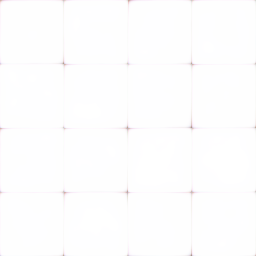

Epoch 41/50 Step 0 — D: 4.0141, G: nan
Epoch 41/50 Step 10 — D: 3.9517, G: 0.4508
Epoch 41 complete — Final D: 3.9517, G: 0.4508
Epoch 42/50 Step 0 — D: 4.0138, G: nan
Epoch 42/50 Step 10 — D: 4.0461, G: 0.3209
Epoch 42 complete — Final D: 4.0461, G: 0.3209
Epoch 43/50 Step 0 — D: 3.9257, G: 0.2883
Epoch 43/50 Step 10 — D: 3.7761, G: 1.2195
Epoch 43 complete — Final D: 3.7761, G: 1.2195
Epoch 44/50 Step 0 — D: 4.0333, G: nan
Epoch 44/50 Step 10 — D: 3.7852, G: 0.4358
Epoch 44 complete — Final D: 3.7852, G: 0.4358
Epoch 45/50 Step 0 — D: 3.7536, G: nan
Epoch 45/50 Step 10 — D: 3.7996, G: 0.9102
Epoch 45 complete — Final D: 3.7996, G: 0.9102
Epoch 46/50 Step 0 — D: 3.8310, G: 1.1031
Epoch 46/50 Step 10 — D: 4.0269, G: 0.0783
Epoch 46 complete — Final D: 4.0269, G: 0.0783
Epoch 47/50 Step 0 — D: 3.9732, G: nan
Epoch 47/50 Step 10 — D: 4.0422, G: -0.2094
Epoch 47 complete — Final D: 4.0422, G: -0.2094
Epoch 48/50 Step 0 — D: 4.0675, G: nan
Epoch 48/50 Step 10 — D: 3.9810, G: 0.4622
Epoch 4

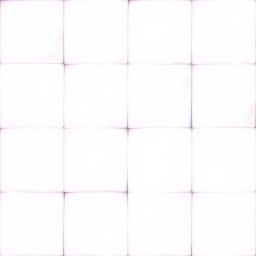

Generating 6378 images for AKIEC...
Done: 6378 images saved for AKIEC.

=== Training GAN for class: BCC ===
Training on 514 real images for class 'BCC'.
Will generate 6191 new images to match max count (6705).


c:\Users\devgo\OneDrive\Desktop\project\.venv\Lib\site-packages\keras\src\layers\layer.py:1474: UserWarning: Layer 'self_attention_2' looks like it has unbuilt state, but Keras is not able to trace the layer `call()` in order to build it automatically. Possible causes:
1. The `call()` method of your layer may be crashing. Try to `__call__()` the layer eagerly on some test input first to see if it works. E.g. `x = np.random.random((3, 4)); y = layer(x)`
2. If the `call()` method is correct, then you may need to implement the `def build(self, input_shape)` method on your layer. It should create all variables used by the layer (e.g. by calling `layer.build()` on all its children layers).
Exception encountered: ''Input 'y' of 'AddV2' Op has type float16 that does not match type float32 of argument 'x'.''
  warnings.warn(


Epoch 1/50 Step 0 — D: 3.9892, G: nan
Epoch 1/50 Step 10 — D: 3.0604, G: nan
Epoch 1 complete — Final D: 4.1569, G: 0.9352
Saved preview: C:\Users\devgo\OneDrive\Desktop\project\data\processed with gan 2\BCC\previews\epoch_001.png


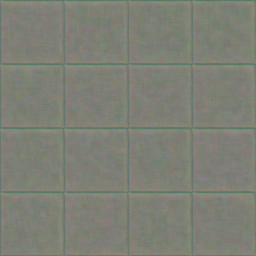

Epoch 2/50 Step 0 — D: 3.4010, G: nan
Epoch 2/50 Step 10 — D: 3.1784, G: nan
Epoch 2 complete — Final D: 3.3260, G: 1.3491
Epoch 3/50 Step 0 — D: 2.9122, G: nan
Epoch 3/50 Step 10 — D: 2.8294, G: nan
Epoch 3 complete — Final D: 2.9673, G: 2.1461
Epoch 4/50 Step 0 — D: 2.7034, G: nan
Epoch 4/50 Step 10 — D: 4.2347, G: nan
Epoch 4 complete — Final D: 4.0207, G: 0.6650
Epoch 5/50 Step 0 — D: 4.1633, G: nan
Epoch 5/50 Step 10 — D: 3.7506, G: nan
Epoch 5 complete — Final D: 3.5915, G: 1.9824
Epoch 6/50 Step 0 — D: 3.6641, G: nan
Epoch 6/50 Step 10 — D: 4.3096, G: nan
Epoch 6 complete — Final D: 4.0364, G: 0.8119
Epoch 7/50 Step 0 — D: 4.0338, G: nan
Epoch 7/50 Step 10 — D: 4.0069, G: 0.4866
Epoch 7 complete — Final D: 3.7879, G: 1.8166
Epoch 8/50 Step 0 — D: 4.0340, G: nan
Epoch 8/50 Step 10 — D: 3.9629, G: nan
Epoch 8 complete — Final D: 3.8567, G: 0.0669
Epoch 9/50 Step 0 — D: 3.8911, G: nan
Epoch 9/50 Step 10 — D: 3.9479, G: nan
Epoch 9 complete — Final D: 3.8691, G: 0.8442
Epoch 10/50 S

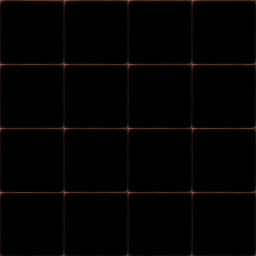

Epoch 11/50 Step 0 — D: 3.9059, G: 0.1390
Epoch 11/50 Step 10 — D: 3.8814, G: 0.4410


In [ ]:
for class_folder in sorted(os.listdir(BASE_DIR)):
    class_path = os.path.join(BASE_DIR, class_folder)
    if not os.path.isdir(class_path):
        continue
    out_folder = os.path.join(OUT_BASE, class_folder)
    train_custom_gan_per_class(class_folder, class_path, out_folder)
